# Missing values

A missing value is a cell that should hold a value and doesn't. Most models can't take one, so every missing value has to be removed, filled, or left to a model that accepts it. Which of these is right depends less on how many values are missing than on **why** they are missing.

## Unknown, or not applicable

Two checks come before any decision, and both are fixed rules applied when the table is built ([Finding the problems in a table](../../pia/python-data-essentials/README.md) *(coming)*):

- **Placeholders.** A missing value may be stored as something else: 0, −1, 999, `"?"`, `"unknown"`, an empty string. pandas sees a value; it must become a real missing value (`NaN`) first. [Pima diabetes](../supervised-learning/basic-workflows/pima_diabetes.ipynb) has insulin levels of 0 that are measurements never taken.
- **Not applicable.** A value may be absent because it doesn't exist, not because it is unknown: the date of the last change of owner, for a car that never had one. That absence is information, a value of its own ("no change of owner"), and is encoded as such, not filled as if it were unknown.

What remains are values that exist but weren't recorded. They are the subject of this notebook.

## A small table

Six cars, with the mileage of two and the fuel of one unknown:

In [ ]:
import numpy as np
import pandas as pd

cars = pd.DataFrame({
    "km": [98_500, np.nan, 187_000, 12_900, np.nan, 120_750],
    "fuel": ["diesel", "petrol", None, "electric", "petrol", "hybrid"],
    "price": [9_800, 11_500, 3_900, 24_900, 14_200, 4_500],
})
cars

,km,fuel,price
0,98500.0,diesel,9800
1,NaN,petrol,11500
2,187000.0,NaN,3900
3,12900.0,electric,24900
4,NaN,petrol,14200
5,120750.0,hybrid,4500


In [ ]:
cars.isna().sum()

km       2
fuel     1
price    0
dtype: int64

Dropping every row with a missing value:

In [ ]:
cars.dropna()

,km,fuel,price
0,98500.0,diesel,9800
3,12900.0,electric,24900
5,120750.0,hybrid,4500


Three cells out of eighteen were missing, and half of the rows are gone, with the values they had in their complete columns. Dropping every column with a missing value instead:

In [ ]:
cars.dropna(axis="columns")

,price
0,9800
1,11500
2,3900
3,24900
4,14200
5,4500


Only the price is left. Filling each gap instead: the mileage with the median of the known mileages, the fuel with the most frequent fuel:

In [ ]:
cars.fillna({"km": cars["km"].median(), "fuel": cars["fuel"].mode()[0]})

,km,fuel,price
0,98500.0,diesel,9800
1,109625.0,petrol,11500
2,187000.0,petrol,3900
3,12900.0,electric,24900
4,109625.0,petrol,14200
5,120750.0,hybrid,4500


Both cars of unknown mileage get 109,625 km, the middle of the four known values. Yet their prices, 11,500 and 14,200, are among the highest, and in this table the dearer cars have the lower mileages: the other columns say something about the missing value that the median ignores. Filling from the other columns is possible too, further down.

One trap of older code, Aurélien Géron's *Hands-On Machine Learning* among it: `cars["km"].fillna(median, inplace=True)` changes nothing since pandas 3, and only warns. Assign the result instead: `cars["km"] = cars["km"].fillna(median)`.

## Why a value is missing

Statisticians distinguish three mechanisms, and what each option assumes depends on them:

- **Missing completely at random (MCAR).** Whether a value is missing has nothing to do with any value, recorded or not: a page of a form lost, a sensor that fails for a few minutes whatever it measures. The rows with the value missing are a random sample of all the rows.
- **Missing at random (MAR).** Whether a value is missing depends only on other columns that *are* recorded. In a survey where women report their weight less often than men, the weight is MAR if, among women and among men separately, who reports it is a matter of chance. The name is confusing: the gaps are not random overall, only once the recorded columns are taken into account.
- **Missing not at random (MNAR).** Whether a value is missing depends on something not recorded, often the missing value itself: people with very high debts are less likely to declare them; a thermometer that can't read above 100 °C records nothing when it is hotter.

The data can rule out MCAR: if the rows with a gap differ from the others in their recorded columns, the gaps are not a random sample. The data can't tell MAR from MNAR, because the evidence for MNAR is in the values that are missing. That last step needs knowledge of how the data were collected.

## The Titanic passengers

The passengers of the Titanic, from OpenML: one row per passenger, and whether they survived as the target. The features kept are the class (`pclass`), the sex, the age, the numbers of siblings or spouses (`sibsp`) and of parents or children (`parch`) aboard, the fare, the port where they embarked and the cabin. Three kinds of column are left out: those recorded after the sinking, the lifeboat and the body number, which would leak the answer; the identifiers, name and ticket; and the free text, home and destination ([Kinds of features](deep-dives/kinds_of_features.ipynb) explains each kind). The gaps are explored on the training rows only, like everything that may shape the model ([Exploring a dataset](deep-dives/exploring_a_dataset.ipynb)):

In [ ]:
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

passengers = fetch_openml("titanic", version=1, as_frame=True, data_home="data").frame
features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "cabin"]
X = passengers[features]
y = passengers["survived"].astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train.isna().sum()

pclass        0
sex           0
age         209
sibsp         0
parch         0
fare          1
embarked      0
cabin       822
dtype: int64

Three columns have gaps in the training rows: the cabin, for most passengers; the age, for about one in five; the fare, for one. Is the age missing at random? The share of passengers without an age, in each class:

In [ ]:
X_train["age"].isna().groupby(X_train["pclass"]).mean().round(2)

pclass
1    0.10
2    0.06
3    0.29
Name: age, dtype: float64

And the survival rate of the passengers with and without a recorded age:

In [ ]:
y_train.groupby(X_train["age"].isna().rename("age missing")).mean().round(2)

age missing
False    0.41
True     0.28
Name: survived, dtype: float64

The age is missing far more often in third class, and the passengers without an age survived less often. The gaps are not a random sample of the passengers: the age is not MCAR. Its gaps depend at least on the class, which is recorded. If the recorded columns explain them completely, the age is MAR; if they also depend on the passengers' own ages, it is MNAR. The data can't tell which: that needs knowing how the passenger list was compiled.

The cabin, the same way:

In [ ]:
X_train["cabin"].isna().groupby(X_train["pclass"]).mean().round(2)

pclass
1    0.20
2    0.93
3    0.98
Name: cabin, dtype: float64

In [ ]:
y_train.groupby(X_train["cabin"].isna().rename("cabin missing")).mean().round(2)

cabin missing
False    0.65
True     0.31
Name: survived, dtype: float64

The cabin is known for most first-class passengers and almost no one else, and the passengers with a known cabin survived about twice as often. Whether the cabin is missing says more than the cabin itself.

The port of embarkation has no gap in the training rows, but the whole passenger list has two. Checking which rows they are is a check of the data, which may look at every row:

In [ ]:
passengers.loc[passengers["embarked"].isna(), ["name", "pclass", "ticket", "fare", "cabin"]]

,name,pclass,ticket,fare,cabin
168,"Icard, Miss. Amelie",1,113572,80.0,B28
284,"Stone, Mrs. George Nelson (Martha Evelyn)",1,113572,80.0,B28


Two first-class passengers on the same ticket and in the same cabin: one missing record, not a pattern. (The Encyclopedia Titanica, the source of the dataset, says that both boarded at Southampton.) Both fell among the test rows. New data can have gaps in a column that had none in the training data, so a pipeline must be ready to fill every column, not only those with gaps today.

## The options, and what each assumes

| Option | What it assumes | When it fits |
| --- | --- | --- |
| Drop the rows | The rows with gaps are like the others (MCAR), and new rows will have no gaps | Very few gaps, a large table |
| Drop the column | The column isn't worth what it costs | A column missing almost everywhere, whose absence says nothing |
| Fill with a statistic | Every missing value is like a typical value | Few gaps, or a quick first model |
| Flag the gap | Being missing may itself be informative | Whenever the gaps are not MCAR; combined with a fill |
| Fill from similar rows, or from the other columns | The gap can be predicted from the recorded columns (MAR) | Gaps related to other columns, as the age to the class |
| Leave it to the model | The model can learn where missing values should go | Models that accept missing values: scikit-learn's trees, random forests and histogram gradient boosting, and XGBoost |

No option recovers MNAR values: the information needed is not in the data. For prediction, though, the gap itself may be informative, which flagging keeps.

## Dropping rows

Dropping the passengers without an age, and comparing what is left with the whole training set:

In [ ]:
with_age = X_train["age"].notna()
pd.DataFrame({
    "all training passengers": [y_train.mean(), (X_train["pclass"] == 3).mean()],
    "only those with an age": [y_train[with_age].mean(), (X_train.loc[with_age, "pclass"] == 3).mean()],
}, index=["survival rate", "share in third class"]).round(3)

,all training passengers,only those with an age
survival rate,0.382,0.407
share in third class,0.552,0.487


The passengers who are left survived more often and are less often in third class: they are no longer a sample of the passengers, and a model trained on them learns a slightly different world. This is a **selection bias**, and it appears whenever the dropped rows are not MCAR.

There is a second, more practical problem: the model will also be asked about new rows with missing values. Rows can be dropped from the training data, not from the data it will be used on.

## Dropping a column, keeping what its absence says

The cabin is missing for most passengers, so as a value it is nearly useless. But its absence is informative, so dropping the column would lose that. A column that says whether the cabin was recorded keeps it:

In [ ]:
X_train_cabin = X_train.assign(cabin_known=X_train["cabin"].notna()).drop(columns="cabin")
X_train_cabin.head()

,pclass,sex,age,sibsp,parch,fare,embarked,cabin_known
999,3,female,NaN,0,0,7.7500,Q,False
392,2,female,24.0,1,0,27.7208,C,False
628,3,female,11.0,4,2,31.2750,S,False
1165,3,male,25.0,0,0,7.2250,C,False
604,3,female,16.0,0,0,7.6500,S,False


This is a fixed rule (it learns nothing from the data), so it could be applied to every row before the split. The deck, the first letter of the cabin, would be a feature for the passengers whose cabin is known ([Creating features](deep-dives/creating_features.ipynb)).

## Filling with a statistic

scikit-learn's `SimpleImputer` learns a value for each column with `fit` (the mean, the median, the most frequent value, or a constant) and fills the gaps with it with `transform`. The median of the training ages:

In [ ]:
from sklearn.impute import SimpleImputer

median_imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
median_imputer.fit(X_train[["age"]])
median_imputer.statistics_

array([28.])

The median rather than the mean, because it is not pulled by extreme values ([Outliers and capped values](deep-dives/outliers.ipynb)). Every passenger without an age gets 28. The ages before and after filling:

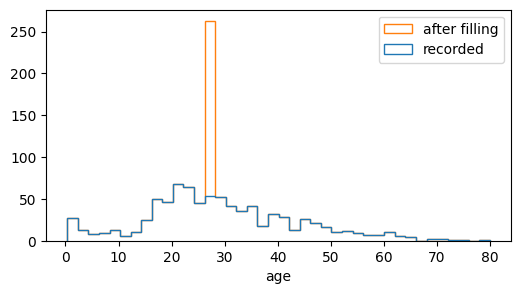

In [ ]:
import matplotlib.pyplot as plt

filled_age = median_imputer.transform(X_train[["age"]])["age"]
plt.figure(figsize=(6, 3))
plt.hist([X_train["age"].dropna(), filled_age], bins=40, label=["recorded", "after filling"], histtype="step")
plt.xlabel("age")
plt.legend();

In [ ]:
pd.DataFrame({
    "standard deviation": [X_train["age"].std(), filled_age.std()],
    "median of first class": [X_train.loc[X_train["pclass"] == 1, "age"].median(), filled_age[X_train["pclass"] == 1].median()],
    "median of third class": [X_train.loc[X_train["pclass"] == 3, "age"].median(), filled_age[X_train["pclass"] == 3].median()],
}, index=["recorded", "after filling"]).round(1)

,standard deviation,median of first class,median of third class
recorded,14.4,38.0,24.0
after filling,12.9,36.0,28.0


Filling with one value has three effects, visible here:

- **A spike** at 28: over 200 passengers now have exactly the same age.
- **Less variation**: the standard deviation falls from about 14.4 to 12.9 years, because every filled value sits in the middle.
- **Weaker relationships**: third-class passengers were younger, and the missing ages, mostly in third class, have been filled with an age taken from all classes. A model now sees a weaker link between class and age than there was.

For categories, `strategy="most_frequent"` fills with the most common value: Southampton, for the port of embarkation.

## Flagging the gap

Since the passengers without an age survived less often, the fact that the age is missing is information worth keeping. `add_indicator=True` adds a column that says, for each row, whether the value was filled:

In [ ]:
flagging_imputer = SimpleImputer(strategy="median", add_indicator=True).set_output(transform="pandas")
flagging_imputer.fit_transform(X_train[["age"]]).head()

,age,missingindicator_age
999,28.0,1.0
392,24.0,0.0
628,11.0,0.0
1165,25.0,0.0
604,16.0,0.0


The model can now treat a filled 28 differently from a real 28. Flagging is cheap, and worth trying whenever the gaps are not MCAR.

## Filling from similar rows, or from the other columns *(deep dive)*

Two imputers use the recorded columns to fill each gap differently:

- `KNNImputer` finds, for each passenger with a gap, the *k* passengers most similar in the other columns, and takes the average of their values. Similarity is a distance, so the columns must be scaled first ([Scaling numerical features](feature_scaling.ipynb)).
- `IterativeImputer` predicts each column with gaps from the others with a regression model, and repeats the process for several rounds, each one using the values filled in the previous round. scikit-learn still marks it as experimental: it must be enabled with a special import.

Both work on numbers only. The ages each one gives to a few passengers, next to the median:

In [ ]:
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (enables the import below)
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

numeric = ["pclass", "age", "sibsp", "parch", "fare"]
scaler = StandardScaler().set_output(transform="pandas").fit(X_train[numeric])
knn_imputer = KNNImputer(n_neighbors=5).set_output(transform="pandas").fit(scaler.transform(X_train[numeric]))
iterative_imputer = IterativeImputer(random_state=0).set_output(transform="pandas").fit(X_train[numeric])

missing_age = X_train[X_train["age"].isna()].head(6)
knn_ages = knn_imputer.transform(scaler.transform(missing_age[numeric]))["age"] * scaler.scale_[1] + scaler.mean_[1]
missing_age[["pclass", "sibsp", "parch", "fare"]].assign(
    median=median_imputer.transform(missing_age[["age"]])["age"],
    k_nearest_neighbours=knn_ages,
    iterative=iterative_imputer.transform(missing_age[numeric])["age"],
).round(1)

,pclass,sibsp,parch,fare,median,k_nearest_neighbours,iterative
999,3,0,0,7.8,28.0,36.3,26.9
196,1,0,0,29.7,28.0,49.4,40.1
1292,3,0,0,7.6,28.0,36.1,26.9
1002,3,2,0,23.2,28.0,25.0,20.3
1085,3,0,0,7.3,28.0,38.0,26.9
1116,3,0,0,8.0,28.0,23.7,26.9


The median gives everyone 28. The two other imputers give each passenger an age that depends on their class, their fare and the relatives travelling with them, which is what MAR gaps call for, and they disagree with each other, by more than ten years for some passengers. The `KNNImputer` works on the scaled columns, so its ages are scaled back to years to compare them.

No imputer recovers the real ages; each gives an estimate under its own assumptions, and all of them make the filled values less varied than real ones.

## Leaving it to the model

Some models accept missing values. scikit-learn's decision trees, random forests and histogram gradient boosting (`HistGradientBoostingClassifier` and `HistGradientBoostingRegressor`), and XGBoost ([XGBoost](../supervised-learning/algorithms/tree-based/xgboost.ipynb)), learn at every split of every tree on which side the rows with a missing value should go, choosing the side that reduces the error most. The gaps are not filled at all, and their being missing can be used directly.

## Inside the pipeline

Every fill that computes something from the data (a median, a list of neighbours, a regression model) learns from the rows it sees. Fitted on all the rows, it would carry information from the test rows into the training data ([Data leakage](../supervised-learning/ml-fundamentals/data_leakage.ipynb)). So it is fitted on the training rows, inside the model's pipeline, and applied unchanged to any new row ([Where data preparation ends](where_preparation_ends.ipynb)).

Two of them are the fills of the deep-dive section above: the nearest neighbours fill an age with the average of the five most similar passengers (`KNNImputer`), and the iterative fill predicts it from the other columns (`IterativeImputer`).

Five ways of handling the gaps, each inside a pipeline with the same model, a logistic regression, except the last, which leaves the gaps to gradient boosting. The categories are filled with their most frequent value and one-hot encoded ([Encoding categories](categorical_encoding.ipynb)); the cabin is reduced to whether it is known. Each pipeline is measured by 10-fold cross-validation on the training rows:

In [ ]:
from sklearn.compose import make_column_transformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OneHotEncoder

X_train_model = X_train.assign(cabin_known=X_train["cabin"].notna()).drop(columns="cabin")
categories = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))


def logistic_with(numeric_steps):
    preprocessing = make_column_transformer(
        (make_pipeline(*numeric_steps), numeric),
        (categories, ["sex", "embarked"]),
        remainder="passthrough",
    )
    return make_pipeline(preprocessing, LogisticRegression(max_iter=1000))


candidates = {
    "median": logistic_with([SimpleImputer(strategy="median"), StandardScaler()]),
    "median and flag": logistic_with([SimpleImputer(strategy="median", add_indicator=True), StandardScaler()]),
    "nearest neighbours": logistic_with([StandardScaler(), KNNImputer(n_neighbors=5)]),
    "iterative": logistic_with([IterativeImputer(random_state=0), StandardScaler()]),
    "gradient boosting, gaps left": make_pipeline(
        make_column_transformer((OneHotEncoder(handle_unknown="ignore"), ["sex", "embarked"]), remainder="passthrough"),
        HistGradientBoostingClassifier(random_state=0),
    ),
}
scores = {name: cross_val_score(model, X_train_model, y_train, cv=10) for name, model in candidates.items()}
pd.DataFrame({"mean accuracy": {name: s.mean() for name, s in scores.items()},
              "standard deviation across folds": {name: s.std() for name, s in scores.items()}}).round(3)

,mean accuracy,standard deviation across folds
median,0.776,0.026
median and flag,0.775,0.028
nearest neighbours,0.773,0.018
iterative,0.780,0.022
"gradient boosting, gaps left",0.792,0.046


The four ways of filling the age give the logistic regression almost the same accuracy, within about a point of each other, while the accuracy of a single pipeline varies by two or three points from one fold to the next. Flagging the missing age doesn't help either, probably because its absence mostly says that the passenger was in third class, which the model already knows. On this table, how the age is filled hardly matters to this model; what the earlier sections showed still matters: keep the passengers without an age, and fit every fill on the training rows only. Gradient boosting, which uses the gaps directly, scores a little higher, by less than its own variation across folds.

That is a finding about this table, not a rule: with more gaps, or gaps more closely related to the target, the choice of imputer can matter much more. Measure it, as here, inside the pipeline.